# Lab 3 — Millions of TVs, Who Is Watching?
Name: Alexander Zavadskyi | Group: KM-41

## Setup

In [1]:
import importlib.util, subprocess, sys
required = ['kagglehub', 'pandas', 'numpy', 'pyarrow', 'matplotlib', 'tzdata']
missing = [p for p in required if importlib.util.find_spec(p) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
DATA = kagglehub.dataset_download('shkarupylomaxim/adtech-lab1-tv-panel/versions/4')
for name in ['programs', 'viewings', 'daily_weights', 'viewer_attributes', 'attributes',
             'acr_sessions', 'hh_attributes', 'reference_ratings']:
    globals()[name] = pd.read_parquet(f'{DATA}/{name}.parquet')
days = pd.date_range('2024-10-14', '2024-10-27')
for frame in [programs, daily_weights]:
    frame['broadcast_date'] = pd.to_datetime(frame.broadcast_date)
TEN = set(programs.network_code)
BIG = ['CBS', 'NBC', 'ABC', 'FOX', 'FNC']
assert len(TEN) == 10
assert acr_sessions.session_id.is_unique
assert not daily_weights.duplicated(['respondent_id', 'broadcast_date']).any()
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:.3f}')
print('Dataset version: 4')

C:\Users\leks\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset version: 4


## Task 1.1 — Five questions

**Answer:**

| Source | Grain | Key | Coverage | Weight | Provenance |
|---|---|---|---|---|---|
| acr_sessions | One continuous session on one smart TV | session_id; tv_id identifies a device | Opted-in sets, October 14–27; recognized live/DVR networks, apps and unknown screen time | None: every TV counts equally | Synthetic convenience footprint with an ACR-style fingerprint feed |
| viewings | One person's or household TV's session on one network | viewing_id; respondent_id plus resp_type identifies who/what | Panel, October 1–31, ten networks; R/L people, H households and guest records | Daily projection weights from daily_weights | Synthetic representative panel, with a real October schedule |

The biggest difference is coverage and selection: opted-in devices are not a representative sample of all households or people. Grain also matters: screen recognition cannot establish who is watching, and a single device does not capture every set in its home. Both files are synthetic, so the provenance descriptions refer to the measurement systems they model.

## Task 1.2 — Size and shape

In [2]:
raw = acr_sessions.copy()
for source, dest in [('start_utc', 'start_ts'), ('end_utc', 'end_ts')]:
    raw[dest] = raw[source].dt.tz_convert('America/New_York').dt.tz_localize(None)
raw['duration_sec'] = (raw.end_ts-raw.start_ts).dt.total_seconds()
assert raw.duration_sec.gt(0).all()
edited = raw.loc[raw.duration_sec.ge(60)].copy()
def split_days(frame):
    # Split after the session-level edit: short boundary fragments are retained.
    result = frame.copy()
    result['broadcast_date'] = (result.start_ts-pd.Timedelta(hours=6)).dt.normalize()
    boundary = result.broadcast_date+pd.Timedelta(days=1, hours=6)
    crosses = result.end_ts.gt(boundary)
    tail = result.loc[crosses].copy()
    tail['start_ts'] = boundary.loc[crosses]
    tail['broadcast_date'] += pd.Timedelta(days=1)
    result.loc[crosses, 'end_ts'] = boundary.loc[crosses]
    assert not tail.end_ts.gt(tail.broadcast_date+pd.Timedelta(days=1, hours=6)).any()
    result = pd.concat([result, tail], ignore_index=True)
    result = result.loc[result.broadcast_date.isin(days)].copy()
    result['hours'] = (result.end_ts-result.start_ts).dt.total_seconds()/3600
    return result
raw_days = split_days(raw)
acr = split_days(edited)
raw_tab = raw_days[['tv_id', 'broadcast_date']].drop_duplicates()
tab = acr[['tv_id', 'broadcast_date']].drop_duplicates()
tab_counts = tab.groupby('broadcast_date').size().reindex(days, fill_value=0)
raw_hours = raw_days.hours.sum()/len(raw_tab)
edited_hours = acr.hours.sum()/len(tab)
drop_share = 1-len(edited)/len(raw)
print('TVs:', raw.tv_id.nunique())
print('Sessions:', len(raw))
print('Broadcast days:', tab.broadcast_date.nunique())
print('Average TVs in-tab per day:', f'{tab_counts.mean():.1f}')
print('Hours per TV per day, raw:', f'{raw_hours:.2f}')
print('Hours per TV per day, after edit rule:', f'{edited_hours:.2f}')
print('Share of sessions dropped:', f'{drop_share:.3f}')
print('Raw TV-days:', len(raw_tab))
print('Edited TV-days:', len(tab))

TVs: 29940
Sessions: 6392981
Broadcast days: 14
Average TVs in-tab per day: 29090.1
Hours per TV per day, raw: 4.73
Hours per TV per day, after edit rule: 4.70
Share of sessions dropped: 0.299
Raw TV-days: 407268
Edited TV-days: 407261


## Task 1.3 — What the TV could not see

In [3]:
for field in ['session_type', 'input_source']:
    shares = (acr.groupby(field).hours.sum()/acr.hours.sum()).rename('share of hours')
    display(shares.to_frame().style.format({'share of hours': '{:.3f}'}))
unknown_share = acr.loc[acr.session_type.eq('unknown'), 'hours'].sum()/acr.hours.sum()
print('Share of TV-on hours unknown (%):', f'{unknown_share*100:.1f}')

,share of hours
session_type,
app,0.257
dvr,0.025
live,0.322
unknown,0.396


,share of hours
input_source,
antenna,0.086
built_in_app,0.307
cable_box,0.276
game_or_disc,0.024
satellite_box,0.076
streaming_device,0.231


Share of TV-on hours unknown (%): 39.6


**Answer:** Unknown hours are screen-on time, not identified network viewing. A real feed can have a less complete fingerprint reference library, recognition failures, and a broader mix of inputs than this controlled synthetic example. A streaming title absent from the library and gameplay or a disc through an external input can both appear as unknown; an unrecognized local channel is another example. The handout's 66% real-sample figure is context, not an estimate obtained from this dataset, and known app sessions should not be conflated with unknown ones.

## Task 2.1 — Match

In [4]:
tv_ips = raw[['tv_id', 'hashed_ip']].drop_duplicates()
assert tv_ips.tv_id.is_unique
ip_counts = hh_attributes.groupby('hashed_ip').household_id.nunique()
tv_ips['households_at_ip'] = tv_ips.hashed_ip.map(ip_counts).fillna(0).astype(int)
match_shares = pd.Series({'one': tv_ips.households_at_ip.eq(1).mean(),
                         'several': tv_ips.households_at_ip.gt(1).mean(),
                         'none': tv_ips.households_at_ip.eq(0).mean()})
unique_hh = hh_attributes.loc[hh_attributes.hashed_ip.map(ip_counts).eq(1)].drop_duplicates('hashed_ip')
matched = tv_ips.loc[tv_ips.households_at_ip.eq(1)].merge(unique_hh, on='hashed_ip', validate='many_to_one')
assert matched.tv_id.is_unique and np.isclose(match_shares.sum(), 1)
print('Matched to one household (%):', f'{match_shares["one"]*100:.1f}')
print('Shared IP, unresolved (%):', f'{match_shares["several"]*100:.1f}')
print('Not matched (%):', f'{match_shares["none"]*100:.1f}')

Matched to one household (%): 65.2
Shared IP, unresolved (%): 11.8
Not matched (%): 22.9


**Answer:** An IP identifies a connection, not a stable person or household. Apartment buildings can share an address, addresses can be reassigned, and devices may move or use VPNs. Hashing hides the address but does not repair these identity ambiguities. Only TVs with exactly one candidate household enter the demographic profile; all edited in-tab TVs, including unmatched ones, remain in the unweighted ratings and viewing totals.

## Task 2.2 — Profile

In [5]:
hh_dw = daily_weights.loc[daily_weights.resp_type.eq('H') & daily_weights.broadcast_date.isin(days)].copy()
hh_mean_weight = hh_dw.groupby('respondent_id').weight.mean()
panel_hh = hh_mean_weight.rename('weight').to_frame()
for field, codes in [('region', range(841, 845)), ('income_band', range(811, 817))]:
    lookup = attributes.set_index('attr_id').attr_name
    flags = viewer_attributes.loc[viewer_attributes.attr_id.isin(codes)].copy()
    assert flags.respondent_id.is_unique
    flags[field] = flags.attr_id.map(lookup)
    panel_hh = panel_hh.join(flags.set_index('respondent_id')[field])
assert panel_hh[['region', 'income_band']].notna().all().all()
income_map = {'Under $25k': 'Under $50k', '$25k-$50k': 'Under $50k',
              '$50k-$75k': '$50-100k', '$75k-$100k': '$50-100k',
              '$100k-$150k': '$100k+', '$150k+': '$100k+'}
matched['income_group'] = matched.income_band.map(income_map)
panel_hh['income_group'] = panel_hh.income_band.map(income_map)
profiles = []
for field in ['region', 'income_group']:
    footprint = matched[field].value_counts(normalize=True)
    us = panel_hh.groupby(field).weight.sum()/panel_hh.weight.sum()
    for group in us.index:
        profiles.append((field, group, footprint.get(group, 0), us[group], footprint.get(group, 0)/us[group]*100))
profile = pd.DataFrame(profiles, columns=['dimension', 'group', 'footprint share', 'panel share', 'index'])
display(profile.style.format({'footprint share': '{:.3f}', 'panel share': '{:.3f}', 'index': '{:.1f}'}))
# Supplement the required income/region profile with the age skew suggested by the handout.
heads = viewer_attributes.loc[viewer_attributes.attr_id.eq(701), 'respondent_id']
ages = viewer_attributes.loc[viewer_attributes.attr_id.eq(300)].set_index('respondent_id').value
head_ages = pd.DataFrame({'household': (heads//100)*100, 'age': heads.map(ages)})
assert head_ages.household.is_unique
panel_hh['head_age'] = panel_hh.index.map(head_ages.set_index('household').age)
assert panel_hh.head_age.notna().all()
print('Heads 65+, footprint share:', f'{matched.head_age_band.eq("65+").mean():.3f}')
print('Heads 65+, panel share:', f'{panel_hh.loc[panel_hh.head_age.ge(65), "weight"].sum()/panel_hh.weight.sum():.3f}')

,dimension,group,footprint share,panel share,index
0,region,Midwest,0.201,0.210,96.0
1,region,Northeast,0.150,0.170,88.0
2,region,South,0.383,0.379,101.0
3,region,West,0.266,0.241,110.4
4,income_group,$100k+,0.421,0.350,120.1
5,income_group,$50-100k,0.320,0.289,110.8
6,income_group,Under $50k,0.259,0.361,71.8


Heads 65+, footprint share: 0.192
Heads 65+, panel share: 0.267


**Answer:** The West is over-represented (index 110.4) and the South is near parity (101.0); the Northeast (88.0) and Midwest (96.0) are under-represented. Homes at $100k+ (120.1) and $50–100k (110.8) are over-represented, while under-$50k homes index only 71.8. Higher-income homes may be more likely to own connected smart TVs and opt into measurement; this is a plausible selection mechanism, not a causal conclusion from these files. The supplementary head-age check also shows too few 65+ homes: 0.192 of matched TVs versus 0.267 of the weighted panel. Profiling only uniquely matched TVs may introduce additional matching selection.

## Task 2.3 — Ratings

In [6]:
def watchers(t, sessions, id_col):
    g = sessions.loc[sessions.network_code.eq(t.network_code) & sessions.start_ts.lt(t.end_ts) & sessions.end_ts.gt(t.start_ts)]
    minutes = (g.end_ts.clip(upper=t.end_ts)-g.start_ts.clip(lower=t.start_ts)).dt.total_seconds()/60
    return set(g.loc[minutes.ge(1), id_col])
live = acr.loc[acr.session_type.eq('live')].copy()
refs = programs.merge(reference_ratings, on='telecast_id', validate='one_to_one')
rating_rows = []
tv_watchers = {}
for t in refs.itertuples(index=False):
    eligible = set(tab.loc[tab.broadcast_date.eq(t.broadcast_date), 'tv_id'])
    seen = watchers(t, live, 'tv_id') & eligible
    tv_watchers[t.telecast_id] = seen
    rating = len(seen)/len(eligible)*100
    rating_rows.append({'telecast_id': t.telecast_id, 'telecast': f'{t.program_name} ({t.network_code})',
        'date': t.broadcast_date.strftime('%Y-%m-%d'), 'TVs HH rating': rating,
        'reference HH rating': t.hh_rating, 'ratio': rating/t.hh_rating,
        'gap (points)': rating-t.hh_rating, 'in-tab TVs': len(eligible)})
rating_table = pd.DataFrame(rating_rows)
display(rating_table.drop(columns=['telecast_id']).style.format({
    'TVs HH rating': '{:.1f}', 'reference HH rating': '{:.1f}', 'ratio': '{:.3f}', 'gap (points)': '{:.1f}', 'in-tab TVs': '{:.0f}'}))
print('Furthest in absolute points:', rating_table.loc[rating_table['gap (points)'].abs().idxmax(), 'telecast'])
print('Closest in absolute points:', rating_table.loc[rating_table['gap (points)'].abs().idxmin(), 'telecast'])
print('Lowest TV/reference ratio:', rating_table.loc[rating_table.ratio.idxmin(), 'telecast'])
print('Highest TV/reference ratio:', rating_table.loc[rating_table.ratio.idxmax(), 'telecast'])

,telecast,date,TVs HH rating,reference HH rating,ratio,gap (points),in-tab TVs
0,The Real Housewives of New York City (BRAVO),2024-10-15,0.7,1.2,0.600,-0.5,29940
1,NCIS (CBS),2024-10-14,5.4,10.6,0.509,-5.2,29940
2,Hannity (FNC),2024-10-16,0.8,2.3,0.359,-1.5,29940
3,Halloween Baking Championship (FOOD),2024-10-14,1.0,1.6,0.604,-0.6,29940
4,MLB Postseason (FOX),2024-10-25,16.5,25.9,0.639,-9.3,29940
5,Grotesquerie (FX),2024-10-16,2.3,3.5,0.641,-1.3,29940
6,Unsellable Houses (HGTV),2024-10-16,2.1,3.7,0.568,-1.6,29940
7,NFL Football (NBC),2024-10-27,21.2,33.1,0.641,-11.9,29940


Furthest in absolute points: NFL Football (NBC)
Closest in absolute points: The Real Housewives of New York City (BRAVO)
Lowest TV/reference ratio: Hannity (FNC)
Highest TV/reference ratio: NFL Football (NBC)


**Answer:** All eight device ratings are below the reference. Sunday Night Football, NFL Football (NBC), has the largest absolute shortfall (11.9 points), while The Real Housewives of New York City (BRAVO) has the smallest (0.5 points); this comparison is influenced by audience size. Relative to its reference, Hannity (FNC) is furthest off (ratio 0.359), while NFL Football (NBC) is closest (0.641, just above Grotesquerie). The especially low ratios for Hannity and NCIS fit the shortage of older homes; the relatively stronger FX/Bravo results fit a younger footprint. Income and region alone do not fully explain program-specific bias. Missing other sets and unrecognized viewing can suppress all ratings at once, so the pattern should not be attributed only to demographic selection.

## Task 3.1 — Hours per home

In [7]:
panel_sessions = viewings.loc[viewings.resp_type.eq('H') & viewings.playback.eq('Live') & viewings.network_code.isin(TEN)].copy()
panel_days = split_days(panel_sessions)
panel_days = panel_days.drop(columns=['weight']).merge(hh_dw[['respondent_id', 'broadcast_date', 'weight']],
    on=['respondent_id', 'broadcast_date'], how='left', validate='many_to_one')
print('Boundary fragments outside panel in-tab (excluded):', int(panel_days.weight.isna().sum()))
# A session can cross 06:00 into a day when that home is not in-tab.
# Only in-tab household-days belong in either numerator or denominator.
panel_days = panel_days.loc[panel_days.weight.notna()].copy()
assert panel_days.weight.notna().all()
panel_days['weighted_hours'] = panel_days.hours*panel_days.weight
tv_ten = live.loc[live.network_code.isin(TEN)].copy()
tv_hours_per_day = tv_ten.hours.sum()/len(tab)
panel_hours_per_day = panel_days.weighted_hours.sum()/hh_dw.weight.sum()
print('Live hours per TV per day (ten networks):', f'{tv_hours_per_day:.2f}')
print('Live hours per panel household per day (ten networks):', f'{panel_hours_per_day:.2f}')
print('Difference (panel minus TVs, hours):', f'{panel_hours_per_day-tv_hours_per_day:.2f}')
print('TV / panel hours ratio:', f'{tv_hours_per_day/panel_hours_per_day:.3f}')

Boundary fragments outside panel in-tab (excluded): 6
Live hours per TV per day (ten networks): 0.87
Live hours per panel household per day (ten networks): 1.92
Difference (panel minus TVs, hours): 1.05
TV / panel hours ratio: 0.452


**Answer:** The TVs report 0.87 live hours per in-tab device-day on the ten networks, compared with 1.92 weighted hours per panel household-day, a gap of 1.05 hours (the TV figure is 45.2% of the panel figure). A footprint device captures only one set, while the household can watch other sets; the lecture's approximately 2.6 sets per home and 1.1 of one brand illustrate this coverage mismatch, not an exact multiplier to apply. Fingerprint failures and opt-in selection can further depress identified live hours, and panel/device definitions are not interchangeable. Both denominators include in-tab non-viewers of these networks, and panel hours use the correct day's household weight after splitting at 06:00; six fragments on days when their household was not in-tab are excluded.

## Task 3.2 — Network shares

In [8]:
network_shares = pd.DataFrame({
    'share in TVs': tv_ten.groupby('network_code').hours.sum()/tv_ten.hours.sum(),
    'share in panel': panel_days.groupby('network_code').weighted_hours.sum()/panel_days.weighted_hours.sum()})
network_shares['index'] = network_shares['share in TVs']/network_shares['share in panel']*100
display(network_shares.style.format({'share in TVs': '{:.3f}', 'share in panel': '{:.3f}', 'index': '{:.1f}'}))
print('Networks overstated:', ', '.join(network_shares.index[network_shares['index'].gt(100)]))
print('Networks understated:', ', '.join(network_shares.index[network_shares['index'].lt(100)]))

,share in TVs,share in panel,index
network_code,,,
ABC,0.196,0.187,104.8
BRAVO,0.016,0.013,122.0
CBS,0.182,0.196,92.8
FNC,0.085,0.110,77.4
FOOD,0.024,0.022,108.9
FOX,0.201,0.194,103.9
FX,0.028,0.022,129.1
HGTV,0.034,0.031,110.4
HIST,0.019,0.019,103.6


Networks overstated: ABC, BRAVO, FOOD, FOX, FX, HGTV, HIST, NBC
Networks understated: CBS, FNC


## Task 3.3 — What each can see

**Answer:** The panel identifies individual R/L viewers, their age and sex, and co-viewing within a household; its daily weights support population estimates including non-viewers. Its household records capture tuning across the home's observed TV viewing rather than just this one opted-in set. The ACR feed gives device-level screen-on timing, input source and known app/unknown usage, and recognized viewing across networks beyond the panel's ten-network extract. App screen time is not necessarily identified content, and neither a fingerprint nor a modeled household attribute proves who watched.

## Task 4.1 — Daily plots

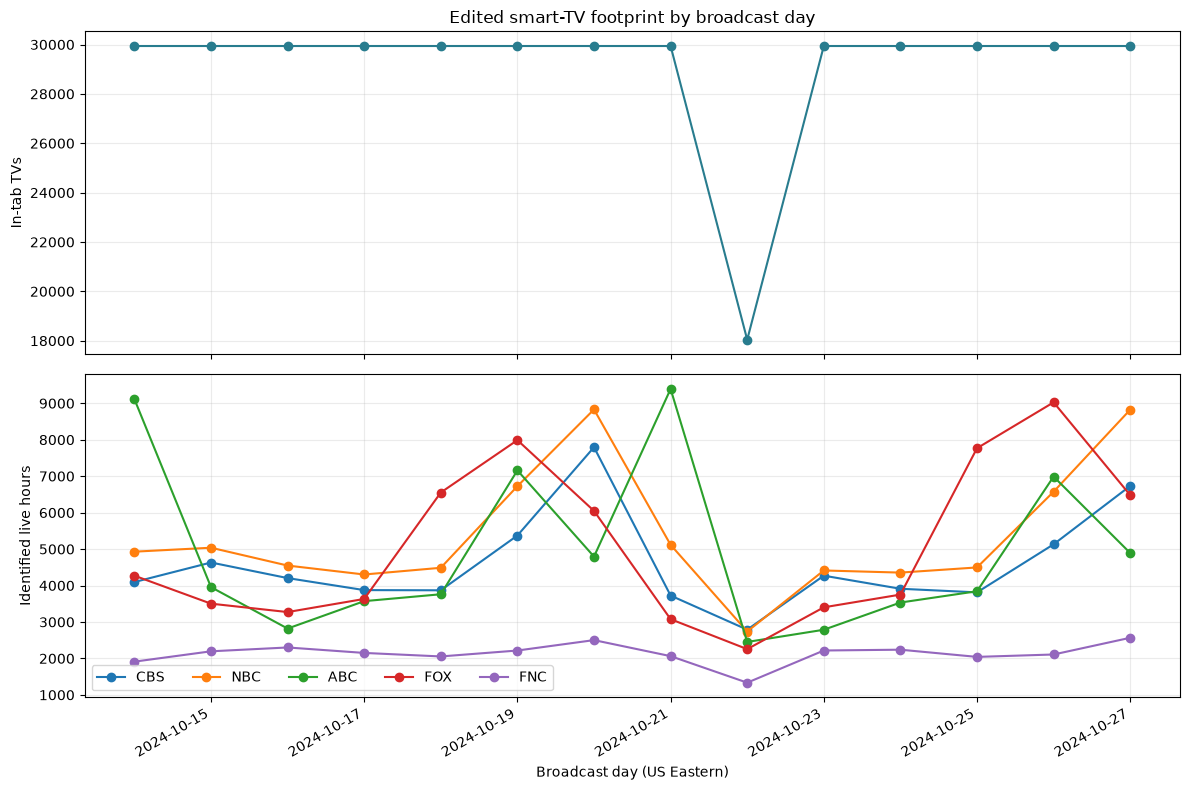

,in-tab TVs,all identified live hours,live hours per in-tab TV
2024-10-14,29940,44012,1.47
2024-10-15,29940,42249,1.41
2024-10-16,29940,42229,1.41
2024-10-17,29940,42074,1.41
2024-10-18,29940,41482,1.39
2024-10-19,29940,51632,1.72
2024-10-20,29940,51737,1.73
2024-10-21,29940,44834,1.50
2024-10-22,18041,25121,1.39
2024-10-23,29940,42340,1.41


In [9]:
daily_live = live.loc[live.network_code.isin(BIG)].groupby(['broadcast_date', 'network_code']).hours.sum().unstack(fill_value=0).reindex(days)
daily_all_live = live.groupby('broadcast_date').hours.sum().reindex(days, fill_value=0)
daily = pd.DataFrame({'in-tab TVs': tab_counts, 'all identified live hours': daily_all_live})
daily['live hours per in-tab TV'] = daily['all identified live hours']/daily['in-tab TVs']
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
axes[0].plot(days, tab_counts, marker='o', color='#287c8e')
axes[0].set(ylabel='In-tab TVs', title='Edited smart-TV footprint by broadcast day')
for network in BIG:
    axes[1].plot(days, daily_live[network], marker='o', label=network)
axes[1].set(ylabel='Identified live hours', xlabel='Broadcast day (US Eastern)')
axes[1].legend(ncol=5)
for ax in axes:
    ax.grid(alpha=.25)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()
daily_display = daily.copy()
daily_display.index = daily_display.index.strftime('%Y-%m-%d')
display(daily_display.style.format({'in-tab TVs': '{:.0f}', 'all identified live hours': '{:.0f}', 'live hours per in-tab TV': '{:.2f}'}))

## Task 4.2 — Spike and broken day

In [10]:
spike_date, spike_net = daily_live.stack().idxmax()
broken_day = tab_counts.idxmin()
print('Biggest spike (date, network):', spike_date.strftime('%Y-%m-%d'), spike_net)
print('Broken day (date):', broken_day.strftime('%Y-%m-%d'))
spike_schedule = programs.loc[programs.broadcast_date.eq(spike_date) & programs.network_code.eq(spike_net)].copy()
spike_schedule['start'] = spike_schedule.start_ts.dt.strftime('%H:%M')
spike_schedule['end'] = spike_schedule.end_ts.dt.strftime('%H:%M')
display(spike_schedule[['program_name', 'episode_name', 'start', 'end']])
print('Broken-day in-tab / other-day median:', f'{tab_counts.loc[broken_day]/tab_counts.drop(broken_day).median():.3f}')
print('Broken-day live hours / other-day median:', f'{daily_all_live.loc[broken_day]/daily_all_live.drop(broken_day).median():.3f}')
print('Broken-day live hours per in-tab TV:', f'{daily.loc[broken_day, "live hours per in-tab TV"]:.2f}')
# Check missing device-days against each device's coverage on the other 13 days.
coverage = tab.groupby('tv_id').broadcast_date.nunique()
print('TVs present every other day but absent on broken day:', int(((coverage.eq(13)) & ~coverage.index.isin(tab.loc[tab.broadcast_date.eq(broken_day), 'tv_id'])).sum()))

Biggest spike (date, network): 2024-10-21 ABC
Broken day (date): 2024-10-22


,program_name,episode_name,start,end
272,Good Morning America,"Alessia Cara, Jenny Slate, Dr. Jill Biden",07:00,09:00
273,Local / Syndicated Programming,NaN,09:00,11:00
274,The View,Tim Walz,11:00,12:00
275,Local / Syndicated Programming,NaN,12:00,13:00
276,GMA3,"Sec. Al Schmidt, Courtney Mason",13:00,14:00
277,General Hospital,Ep. #15573,14:00,15:00
278,Local / Syndicated Programming,NaN,15:00,18:30
279,ABC World News Tonight with David Muir,Episode 283,18:30,19:00
280,Local / Syndicated Programming,NaN,19:00,20:00
281,Who Wants to Be a Millionaire,NaN,20:00,20:15


Broken-day in-tab / other-day median: 0.603
Broken-day live hours / other-day median: 0.589
Broken-day live hours per in-tab TV: 1.39
TVs present every other day but absent on broken day: 11899


**Answer:** The biggest big-network daily spike is ABC on 2024-10-21: the schedule contains Baltimore at Tampa Bay, NFL Football, from 20:15 to 23:25, explaining a genuine sports-driven increase. On 2024-10-22 the in-tab count falls from its usual 29,940 to 18,041: 11,899 TVs present on every other day disappear. Identified live hours fall to 58.9% of the other-day median, but hours per remaining in-tab TV are 1.39, close to the normal weekday level of roughly 1.4. That combination strongly suggests missing device reporting rather than a sudden audience-wide collapse; the files do not identify the technical cause. Using all 29,940 as the denominator would bias that day's rating downward, while using only reporting TVs avoids that mechanical mistake but can still bias the rating if missingness is selective; daily totals would also look like a false decline. Flag the day, seek a vendor backfill and recompute if it arrives; without a validated repair, exclude it from comparable trend estimates or show a sensitivity analysis, rather than inventing lost viewing. The required two-week summaries above retain the observed day transparently.

## Task 5.1 — Sampling error vs bias

In [11]:
se_rows = []
selected = refs.loc[(refs.network_code.eq('NBC') & refs.program_name.eq('NFL Football'))
    | refs.program_name.isin(['Hannity', 'Unsellable Houses'])]
for t in selected.itertuples(index=False):
    r = rating_table.set_index('telecast_id').loc[t.telecast_id]
    n_tv = int(r['in-tab TVs'])
    n_panel = hh_dw.loc[hh_dw.broadcast_date.eq(t.broadcast_date), 'respondent_id'].nunique()
    p = t.hh_rating/100
    se_tv = np.sqrt(p*(1-p)/n_tv)*100
    se_panel = np.sqrt(p*(1-p)/n_panel)*100
    se_rows.append({'telecast': f'{t.program_name} ({t.network_code})', 'in-tab TVs': n_tv,
        'panel HH': n_panel, 'SE footprint': se_tv, 'SE panel': se_panel,
        'panel SE / footprint SE': se_panel/se_tv, 'TVs rating - reference': r['gap (points)'],
        'absolute gap / footprint SE': abs(r['gap (points)'])/se_tv})
se_table = pd.DataFrame(se_rows)
display(se_table.style.format({'in-tab TVs': '{:.0f}', 'panel HH': '{:.0f}',
    'SE footprint': '{:.1f}', 'SE panel': '{:.1f}', 'panel SE / footprint SE': '{:.1f}',
    'TVs rating - reference': '{:.1f}', 'absolute gap / footprint SE': '{:.1f}'}))

,telecast,in-tab TVs,panel HH,SE footprint,SE panel,panel SE / footprint SE,TVs rating - reference,absolute gap / footprint SE
0,Hannity (FNC),29940,3867,0.1,0.2,2.8,-1.5,17.0
1,Unsellable Houses (HGTV),29940,3867,0.1,0.3,2.8,-1.6,14.6
2,NFL Football (NBC),29940,3898,0.3,0.8,2.8,-11.9,43.7


**Answer:** The formula gives a smaller nominal sampling SE for the larger footprint, by the ratios in the table, but its absolute reference gaps are many times those SEs. More devices shrink independent random sampling error; they do not remove selection bias or missing sets and recognition failures. These are illustrative simple-random-sample SEs evaluated at the reference probability, not valid uncertainty bounds for a convenience sample; the panel's weighting and clustering also require a proper design-based variance calculation.

## Task 5.2 — Answer to the planner

**Answer:** For Dallas at San Francisco on 2024-10-27, I can report a 21.2 device-based household-proxy rating from edited live sessions, versus the supplied 33.1 household reference, clearly labeled as an unweighted smart-TV footprint estimate. This is a count of observed sets, so it cannot identify individual people or recover viewing on other sets in a home. App hours and unknown screen time do not supply equivalent identified live-network audiences, and opted-out homes are absent while unmatched homes cannot be reliably profiled. The nominal footprint SE is only 0.3 rating points, but its 11.9-point reference gap is far larger, so sample size does not make this a population currency. Before planning, I would validate household linkage, audit daily reporting and recognition, calibrate demographic coverage, and benchmark all-set and person delivery against an independent panel. I would keep the October 22 reporting failure flagged and use the validated currency for a client guarantee until these coverage and selection problems are resolved.

## Bonus

In [12]:
snf = refs.loc[refs.network_code.eq('NBC') & refs.program_name.eq('NFL Football')].iloc[0]
age = viewer_attributes.loc[viewer_attributes.attr_id.eq(300)].set_index('respondent_id').value
target = set(age.index[age.between(25, 54)])
person_sessions = viewings.loc[viewings.resp_type.isin(['R', 'L'])]
hh_sessions = viewings.loc[viewings.resp_type.eq('H')]
person_seen = watchers(snf, person_sessions, 'respondent_id') & target
hh_seen = watchers(snf, hh_sessions, 'respondent_id')
person_tab = daily_weights.loc[daily_weights.broadcast_date.eq(snf.broadcast_date)
    & daily_weights.resp_type.isin(['R', 'L']) & daily_weights.respondent_id.isin(target)]
hh_tab = hh_dw.loc[hh_dw.broadcast_date.eq(snf.broadcast_date)]
target_viewers = person_tab.loc[person_tab.respondent_id.isin(person_seen), 'weight'].sum()
viewing_hh = hh_tab.loc[hh_tab.respondent_id.isin(hh_seen), 'weight'].sum()
vpvh = target_viewers/viewing_hh
tv_hh_rating = rating_table.set_index('telecast_id').loc[snf.telecast_id, 'TVs HH rating']
person_rating = tv_hh_rating*vpvh*(hh_tab.weight.sum()/person_tab.weight.sum())
print('VPVH A25-54:', f'{vpvh:.3f}')
print('A25-54 rating (persons):', f'{person_rating:.1f}')
print('Panel direct A25-54 rating (persons):', f'{target_viewers/person_tab.weight.sum()*100:.1f}')

VPVH A25-54: 0.513
A25-54 rating (persons): 11.1
Panel direct A25-54 rating (persons): 17.8


**Answer:** This assumes the panel's weighted A25–54 viewers per viewing household transfers to homes in the footprint, including the same composition and co-viewing conditional on tuning. It also treats this device-based household rating as comparable to all-set household viewing and uses consistent broadcast-day universes. Those assumptions are doubtful because opt-in homes differ and other sets are missing; the conversion changes units but cannot cure the original footprint bias. The direct panel rating is shown as a diagnostic, not as a correction fitted into the requested formula.

In [13]:
assert len(rating_table) == 8 and rating_table.telecast_id.is_unique
assert rating_table['TVs HH rating'].between(0, 100).all()
assert np.isclose(match_shares.sum(), 1)
assert np.isclose(network_shares['share in TVs'].sum(), 1)
assert np.isclose(network_shares['share in panel'].sum(), 1)
assert np.isclose(acr.hours.sum(), edited.duration_sec.sum()/3600)
assert tv_hours_per_day > 0 and panel_hours_per_day > 0
assert np.isfinite(vpvh) and 0 <= person_rating <= 100
print('All consistency checks passed.')

All consistency checks passed.
